# RQ1 — Chunking and Retrieval Evaluation

This notebook runs and analyzes **Research Question 1**: which combination of chunking strategy, chunk size, and retrieval method yields the best retrieval quality for ESRS disclosure queries?

**Experimental design** — full 3 × 3 × 6 factorial:

| Factor | Levels |
|---|---|
| Chunking strategy | `fixed`, `structure_aware`, `semantic` |
| Chunk size (tokens) | 256, 512, 1024 |
| Retrieval method | `dense`, `dense_rerank`, `sparse`, `sparse_rerank`, `hybrid_rrf`, `hybrid_rerank` |

**Total: 54 configurations**, each evaluated against the Golden Standard.

**Evaluation coverage**: 204 of 204 question–company pairs are retrieval-evaluable (all 12 ESRS standards have annotated evidence passages). Question–company pairs whose evidence passages have empty text are excluded from metric computation (currently none).

**Primary metric**: Recall@15 — the fraction of gold evidence passages retrieved in the top-15 chunks.

**Key metrics reported**:
- **Recall@k** (k = 5, 10, 15) — coverage of gold evidence passages
- **Precision@k** — fraction of top-k chunks that are relevant
- **F1@k** — harmonic mean of Precision and Recall (balances coverage with noise)
- **nDCG@10** — ranking quality with binary relevance
- **MRR@10** — reciprocal rank of first relevant chunk
- **Budgeted Recall@4096** — recall under a fixed token budget (normalises for chunk size)

**Relevance matching**: A retrieved chunk counts as relevant when it covers ≥ 50% of a gold passage (configurable threshold). Primary path uses span-based character overlap; fallback uses multiplicity-aware token overlap.

**Statistical validation**: Bootstrap confidence intervals (10 000 resamples), paired permutation tests (10 000 permutations), and Cohen's d effect sizes are computed for the top configurations.

## 1. Environment and Imports

Set up the Python path so that `rag.*` modules can be imported from the project root. All core logic resides in the `rag/` package; this notebook only orchestrates calls and visualises results.

In [1]:
# ---------------------------------------------------------------------------
# Path setup: ensure project root is on sys.path so rag.* imports work
# when running from the notebooks/ subdirectory.
# ---------------------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# RQ1_RESULTS_DIR: path to data/artifacts/evaluation_results/rq1/
# build_rq1_experiment_grid: returns list of 54 PipelineConfig objects
from rag.config.settings import RQ1_RESULTS_DIR, build_rq1_experiment_grid

# RQ1PipelineRunner: orchestrates chunking → embedding → retrieval → evaluation
from rag.pipeline.rq1_runner import RQ1PipelineRunner

print(f"Project root: {PROJECT_ROOT}")
print(f"RQ1 result directory: {RQ1_RESULTS_DIR}")

Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ1 result directory: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq1


## 2. Experiment Grid

The full factorial grid produces **54 configurations** (3 chunking strategies × 3 chunk sizes × 6 retrieval methods). Each row below represents one pipeline configuration that will be evaluated independently. The grid is generated by `build_rq1_experiment_grid()` which creates `PipelineConfig` dataclasses with deterministic `config_id` strings (e.g. `fixed_1024_sparse`).

In [2]:
# ---------------------------------------------------------------------------
# Build the full 3 × 3 × 6 = 54 configuration grid.
# Each PipelineConfig specifies chunk_strategy, chunk_size, retrieval_method,
# plus fixed hyperparameters (overlap ratio, top_k, rrf_k, rerank model).
# ---------------------------------------------------------------------------
grid = build_rq1_experiment_grid()
print(f"Total configs: {len(grid)}")

# Display as a DataFrame for visual inspection.
grid_df = pd.DataFrame([
    {"config_id": c.config_id, "chunk_strategy": c.chunk_strategy,
     "chunk_size": c.chunk_size, "retrieval_method": c.retrieval_method}
    for c in grid
])
grid_df

Total configs: 54


,config_id,chunk_strategy,chunk_size,retrieval_method
0,fixed_256_dense,fixed,256,dense
1,fixed_256_dense_rerank,fixed,256,dense_rerank
2,fixed_256_sparse,fixed,256,sparse
3,fixed_256_sparse_rerank,fixed,256,sparse_rerank
4,fixed_256_hybrid_rrf,fixed,256,hybrid_rrf
5,fixed_256_hybrid_rerank,fixed,256,hybrid_rerank
6,fixed_512_dense,fixed,512,dense
7,fixed_512_dense_rerank,fixed,512,dense_rerank
8,fixed_512_sparse,fixed,512,sparse
9,fixed_512_sparse_rerank,fixed,512,sparse_rerank


## 3. Execute the RQ1 Evaluation Pipeline

`RQ1PipelineRunner.run()` iterates over all 54 configurations. For each one it:

1. **Chunks** the 17 reports using the strategy/size pair (cached across retrieval methods sharing the same pair).
2. **Embeds** chunks via OpenAI `text-embedding-3-large` and indexes them in Qdrant (reused if the collection already exists).
3. **Retrieves** top-15 chunks per golden-standard sample using the configured retrieval method (dense, sparse, hybrid, ± reranking).
4. **Computes** Recall@k, Precision@k, F1@k, nDCG@10, MRR@10, and Budgeted Recall@4096 against the golden standard.

Results are persisted incrementally to `config_details/*.json` so interrupted runs can resume. Set `DRY_RUN = True` to test with one configuration only.

**Note:** After code changes (e.g. chunking fix, metric updates), run `python cleanup_rq1_cache.py --include-qdrant-semantic` first to clear cached results.

In [3]:
# ---------------------------------------------------------------------------
# Run the full RQ1 evaluation matrix (54 configs × 204 samples each).
# Set DRY_RUN = True to execute only the first configuration as a smoke test.
#
# Under the hood, RQ1PipelineRunner:
#   - Loads all 17 reports and the 204-sample golden standard
#   - For each config: builds chunks → embeds → indexes → retrieves → evaluates
#   - Persists per-config JSON results incrementally (resume-safe)
#   - Selects the winner by Recall@15 and writes config/best_pipeline.yaml
# ---------------------------------------------------------------------------
DRY_RUN = False

runner = RQ1PipelineRunner(dry_run=DRY_RUN)
summary = runner.run()
summary

/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_256> contains 32426 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_512> contains 30149 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulatio

Running config: fixed_256_dense
  Qdrant collection rq1_esrs_fixed_256 already has 10445 vectors — reusing
  -> completed: recall@15 = 0.0858  (span match: 41.9%, token fallback: 9494 checks)
Running config: fixed_256_dense_rerank


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  -> completed: recall@15 = 0.1507  (span match: 42.7%, token fallback: 9002 checks)
Running config: fixed_256_sparse
  -> completed: recall@15 = 0.7596  (span match: 43.6%, token fallback: 6774 checks)
Running config: fixed_256_sparse_rerank
  -> completed: recall@15 = 0.7757  (span match: 44.6%, token fallback: 6565 checks)
Running config: fixed_256_hybrid_rrf
  -> completed: recall@15 = 0.6345  (span match: 43.9%, token fallback: 7570 checks)
Running config: fixed_256_hybrid_rerank
  -> completed: recall@15 = 0.7753  (span match: 44.5%, token fallback: 6554 checks)
Running config: fixed_512_dense
  Qdrant collection rq1_esrs_fixed_512 already has 5226 vectors — reusing
  -> completed: recall@15 = 0.2293  (span match: 42.4%, token fallback: 7055 checks)
Running config: fixed_512_dense_rerank
  -> completed: recall@15 = 0.3592  (span match: 43.7%, token fallback: 6529 checks)
Running config: fixed_512_sparse
  -> completed: recall@15 = 0.8946  (span match: 43.9%, token fallback: 5707 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Qdrant collection rq1_esrs_semantic_256 already has 32426 vectors — reusing
  -> completed: recall@15 = 0.1133  (span match: 41.3%, token fallback: 4669 checks)
Running config: semantic_256_dense_rerank
  -> completed: recall@15 = 0.1721  (span match: 41.4%, token fallback: 8359 checks)
Running config: semantic_256_sparse
  -> completed: recall@15 = 0.7278  (span match: 43.4%, token fallback: 7023 checks)
Running config: semantic_256_sparse_rerank
  -> completed: recall@15 = 0.7431  (span match: 43.8%, token fallback: 6821 checks)
Running config: semantic_256_hybrid_rrf
  -> completed: recall@15 = 0.6669  (span match: 43.0%, token fallback: 7455 checks)
Running config: semantic_256_hybrid_rerank
  -> completed: recall@15 = 0.7396  (span match: 43.6%, token fallback: 6837 checks)
Running config: semantic_512_dense
  Qdrant collection rq1_esrs_semantic_512 already has 30149 vectors — reusing
  -> completed: recall@15 = 0.1852  (span match: 42.5%, token fallback: 3315 checks)
Running co

{'winner': 'fixed_1024_sparse',
 'winner_metrics': {'recall@5': 0.8687091503267974,
  'recall@10': 0.923202614379085,
  'recall@15': 0.948937908496732,
  'precision@5': 0.669607843137255,
  'precision@10': 0.578921568627451,
  'precision@15': 0.526797385620915,
  'f1@5': 0.7238506147959983,
  'f1@10': 0.6695378722874472,
  'f1@15': 0.6272182682145788,
  'ndcg@10': 0.7901577278903814,
  'mrr@10': 0.8813783846872082,
  'budgeted_recall@4096': 0.8200980392156862,
  'recall@15_std': 0.162131108672352,
  'precision@15_std': 0.2966715268946089,
  'f1@15_std': 0.27518224562514576,
  'ndcg@10_std': 0.2129737626707145,
  'mrr@10_std': 0.2567409239698513},
 'evaluated_configs': 54}

## 4. Load Persisted Results

The pipeline writes `rq1_config_results.csv` and `.json` after each completed configuration. We reload the CSV here so the analysis cells below work independently of whether the pipeline was just executed or results were loaded from a previous run.

In [4]:
# ---------------------------------------------------------------------------
# Load the persisted CSV so all analysis cells below work independently
# of whether the pipeline was just executed or loaded from a previous run.
# The CSV contains one row per configuration with all aggregate metrics.
# ---------------------------------------------------------------------------
results_csv = RQ1_RESULTS_DIR / "rq1_config_results.csv"

df = pd.read_csv(results_csv)
print(f"Loaded {len(df)} configuration results")
print(f"Columns: {list(df.columns)}")

# Show all 54 configs ranked by the primary metric (Recall@15).
df.sort_values("recall@15", ascending=False).head(54)

Loaded 54 configuration results
Columns: ['config_id', 'chunk_strategy', 'chunk_size', 'retrieval_method', 'recall@5', 'recall@10', 'recall@15', 'precision@5', 'precision@10', 'precision@15', 'f1@5', 'f1@10', 'f1@15', 'ndcg@10', 'mrr@10', 'budgeted_recall@4096', 'recall@15_std', 'precision@15_std', 'f1@15_std', 'ndcg@10_std', 'mrr@10_std']


,config_id,chunk_strategy,chunk_size,retrieval_method,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,...,f1@10,f1@15,ndcg@10,mrr@10,budgeted_recall@4096,recall@15_std,precision@15_std,f1@15_std,ndcg@10_std,mrr@10_std
0,fixed_1024_sparse,fixed,1024,sparse,0.868709,0.923203,0.948938,0.669608,0.578922,0.526797,...,0.669538,0.627218,0.790158,0.881378,0.820098,0.162131,0.296672,0.275182,0.212974,0.256741
1,fixed_1024_hybrid_rerank,fixed,1024,hybrid_rerank,0.830474,0.910131,0.941176,0.657843,0.581863,0.534967,...,0.657955,0.623710,0.784550,0.847152,0.768791,0.148928,0.314610,0.286285,0.189266,0.274551
2,fixed_1024_sparse_rerank,fixed,1024,sparse_rerank,0.823938,0.910131,0.937908,0.651961,0.580392,0.540523,...,0.659527,0.627781,0.776251,0.841025,0.765931,0.162167,0.315053,0.286846,0.198500,0.281981
3,structure_aware_1024_sparse,structure_aware,1024,sparse,0.794363,0.878268,0.919526,0.543137,0.439706,0.396078,...,0.548998,0.511877,0.716769,0.815470,0.813725,0.197546,0.248445,0.251590,0.227387,0.318664
4,structure_aware_1024_sparse_rerank,structure_aware,1024,sparse_rerank,0.764297,0.870507,0.915033,0.514706,0.429412,0.392157,...,0.537878,0.504971,0.701944,0.790747,0.792075,0.215212,0.257527,0.260886,0.240086,0.329623
5,structure_aware_1024_hybrid_rerank,structure_aware,1024,hybrid_rerank,0.764297,0.865196,0.912582,0.514706,0.433824,0.393137,...,0.541948,0.507441,0.702910,0.792128,0.797794,0.219586,0.253658,0.258505,0.242525,0.328264
6,fixed_512_sparse_rerank,fixed,512,sparse_rerank,0.748203,0.862337,0.911356,0.565686,0.475000,0.416340,...,0.571175,0.525032,0.725035,0.794763,0.815768,0.209432,0.273946,0.269441,0.246004,0.331734
7,semantic_1024_sparse,semantic,1024,sparse,0.783333,0.864216,0.904412,0.534314,0.418137,0.368627,...,0.529061,0.485871,0.719913,0.811502,0.810703,0.216138,0.238074,0.249547,0.240140,0.325454
8,semantic_1024_hybrid_rerank,semantic,1024,hybrid_rerank,0.757190,0.860948,0.903431,0.502941,0.415686,0.372222,...,0.526618,0.486798,0.700386,0.804320,0.805392,0.227265,0.243473,0.249451,0.244938,0.327669
9,fixed_512_hybrid_rerank,fixed,512,hybrid_rerank,0.745752,0.858660,0.897059,0.565686,0.472549,0.409477,...,0.569585,0.518936,0.729585,0.796650,0.817402,0.227783,0.268991,0.268048,0.253208,0.331872


### Integrity Check

Verify that the loaded results match the expected experiment design:
- Exactly 3 strategies × 3 sizes × 6 methods = 54 rows.
- Rerank variants produce different metrics from their base methods (confirming the cross-encoder is active and not a no-op).

In [5]:
# ---------------------------------------------------------------------------
# Integrity check: ensure the CSV contains exactly the expected factorial.
# This guards against incomplete runs or corrupted result files.
# ---------------------------------------------------------------------------
expected_strategies = {"fixed", "structure_aware", "semantic"}
expected_sizes = {256, 512, 1024}
expected_methods = {"dense", "dense_rerank", "sparse", "sparse_rerank", "hybrid_rrf", "hybrid_rerank"}

actual_strategies = set(df["chunk_strategy"].unique())
actual_sizes = set(df["chunk_size"].unique())
actual_methods = set(df["retrieval_method"].unique())

assert actual_strategies == expected_strategies, f"Strategy mismatch: {actual_strategies}"
assert actual_sizes == expected_sizes, f"Size mismatch: {actual_sizes}"
assert actual_methods == expected_methods, f"Method mismatch: {actual_methods}"
assert len(df) == len(expected_strategies) * len(expected_sizes) * len(expected_methods), (
    f"Expected {len(expected_strategies) * len(expected_sizes) * len(expected_methods)} configs, got {len(df)}"
)

# Verify that each rerank variant differs from its base method.
# If they are identical, the cross-encoder may not be loading correctly.
rerank_pairs = [
    ("dense", "dense_rerank"),
    ("sparse", "sparse_rerank"),
    ("hybrid_rrf", "hybrid_rerank"),
]
identical_count = 0
for base, rerank in rerank_pairs:
    idx_cols = ["chunk_strategy", "chunk_size"]
    base_s = df.loc[df["retrieval_method"] == base, idx_cols + ["recall@15"]].set_index(idx_cols).sort_index()["recall@15"]
    rerank_s = df.loc[df["retrieval_method"] == rerank, idx_cols + ["recall@15"]].set_index(idx_cols).sort_index()["recall@15"]
    if (base_s.values == rerank_s.values).all():
        identical_count += 1
        print(f"WARNING: {base} and {rerank} have identical recall@15 — reranker may not be active")

if identical_count == 0:
    print("Rerank integrity: all rerank variants differ from their base methods.")

print(f"\nIntegrity check passed: {len(df)} configs, "
      f"{len(actual_strategies)} strategies, {len(actual_sizes)} sizes, {len(actual_methods)} methods.")

Rerank integrity: all rerank variants differ from their base methods.

Integrity check passed: 54 configs, 3 strategies, 3 sizes, 6 methods.


## 5. Main Effects Analysis

Main effects isolate the **average contribution of each factor** by averaging Recall@15 across all levels of the other two factors. For example, the main effect of chunking strategy averages over all 3 sizes × 6 methods = 18 configurations per strategy.

This analysis reveals whether a factor has a consistently strong or weak effect regardless of how the other factors are set. A large main effect indicates the factor is important; a small one suggests it matters less than the other factors.

Both Recall@15 (primary) and F1@15 (balanced precision–recall) are shown.

=== Main effect: Chunking Strategy ===


,chunk_strategy,recall@15
2,structure_aware,0.672989
0,fixed,0.663308
1,semantic,0.625822



=== Main effect: Chunk Size ===


,chunk_size,recall@15
2,1024,0.756413
1,512,0.641408
0,256,0.564297



=== Main effect: Retrieval Method ===


,retrieval_method,recall@15
2,hybrid_rerank,0.856363
5,sparse_rerank,0.856282
4,sparse,0.854276
3,hybrid_rrf,0.786701
1,dense_rerank,0.332689
0,dense,0.237927


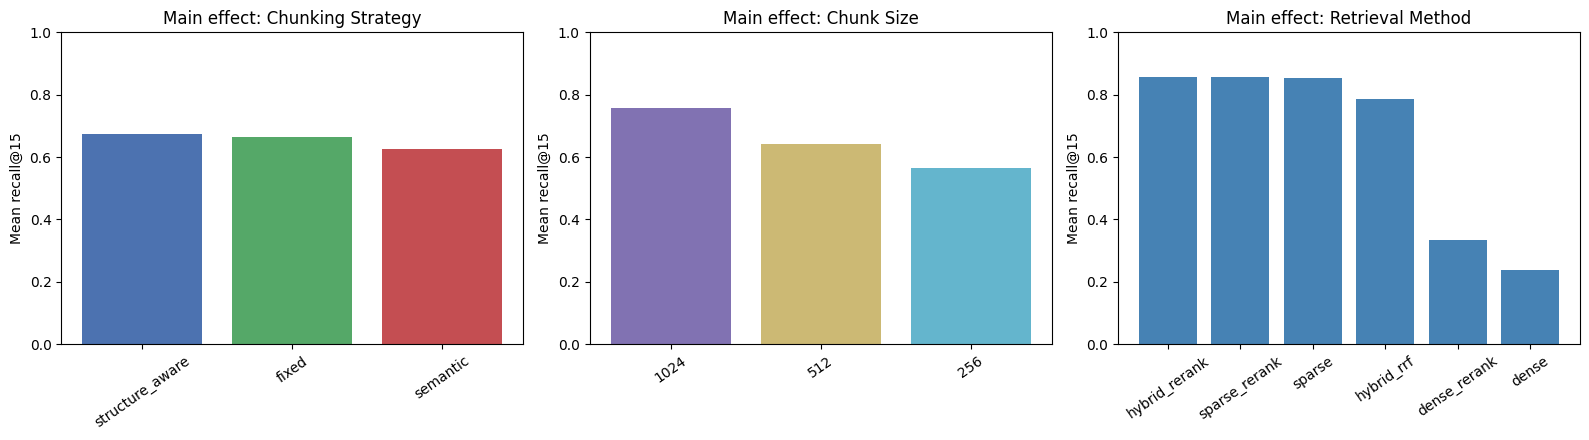


=== Main effects by F1@15 (balanced precision-recall) ===

chunk_strategy:


,chunk_strategy,f1@15
0,fixed,0.373209
2,structure_aware,0.341823
1,semantic,0.288037



chunk_size:


,chunk_size,f1@15
2,1024,0.437754
1,512,0.327210
0,256,0.238105



retrieval_method:


,retrieval_method,f1@15
5,sparse_rerank,0.449523
2,hybrid_rerank,0.448321
4,sparse,0.439716
3,hybrid_rrf,0.380498
1,dense_rerank,0.173512
0,dense,0.114569


In [6]:
# ---------------------------------------------------------------------------
# Main effects: average Recall@15 per factor level.
#
# Why main effects? In a factorial design, the main effect of a factor is
# its average performance across all combinations of the other factors.
# This tells us whether the factor matters "on average", regardless of
# how the other factors are set.
# ---------------------------------------------------------------------------

# Determine which metrics to report (F1@15 may not exist in older results).
has_f1 = "f1@15" in df.columns
report_metric = "recall@15"

main_strategy = df.groupby("chunk_strategy", as_index=False)[report_metric].mean().sort_values(report_metric, ascending=False)
main_size = df.groupby("chunk_size", as_index=False)[report_metric].mean().sort_values(report_metric, ascending=False)
main_retrieval = df.groupby("retrieval_method", as_index=False)[report_metric].mean().sort_values(report_metric, ascending=False)

print("=== Main effect: Chunking Strategy ===")
display(main_strategy)
print("\n=== Main effect: Chunk Size ===")
display(main_size)
print("\n=== Main effect: Retrieval Method ===")
display(main_retrieval)

# --- Bar chart: main effects side by side ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(main_strategy["chunk_strategy"], main_strategy[report_metric], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Main effect: Chunking Strategy")
axes[0].set_ylim(0, 1)

axes[1].bar(main_size["chunk_size"].astype(str), main_size[report_metric], color=["#8172B2", "#CCB974", "#64B5CD"])
axes[1].set_title("Main effect: Chunk Size")
axes[1].set_ylim(0, 1)

axes[2].bar(main_retrieval["retrieval_method"], main_retrieval[report_metric], color="steelblue")
axes[2].set_title("Main effect: Retrieval Method")
axes[2].set_ylim(0, 1)

for ax in axes:
    ax.set_ylabel(f"Mean {report_metric}")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig(RQ1_RESULTS_DIR / "main_effects_recall15.png", dpi=150, bbox_inches="tight")
plt.show()

# --- If F1@15 is available, show that too ---
if has_f1:
    print("\n=== Main effects by F1@15 (balanced precision-recall) ===")
    for name, col in [("chunk_strategy", "chunk_strategy"), ("chunk_size", "chunk_size"), ("retrieval_method", "retrieval_method")]:
        me = df.groupby(col, as_index=False)["f1@15"].mean().sort_values("f1@15", ascending=False)
        print(f"\n{name}:")
        display(me)

## 6. Interaction Heatmaps

Main effects can be misleading if the factors **interact**: the best chunk size under one retrieval method may not be the best under another. The heatmaps below show mean Recall@15 for every pairwise combination, making interaction patterns visible.

If the heatmap rows look roughly parallel, there is no interaction (the effect of one factor is consistent across levels of the other). If they cross or diverge, the interaction is meaningful and should be discussed in the thesis.

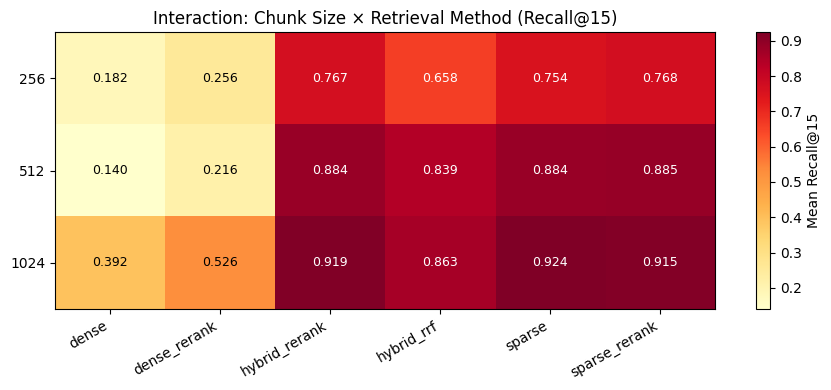

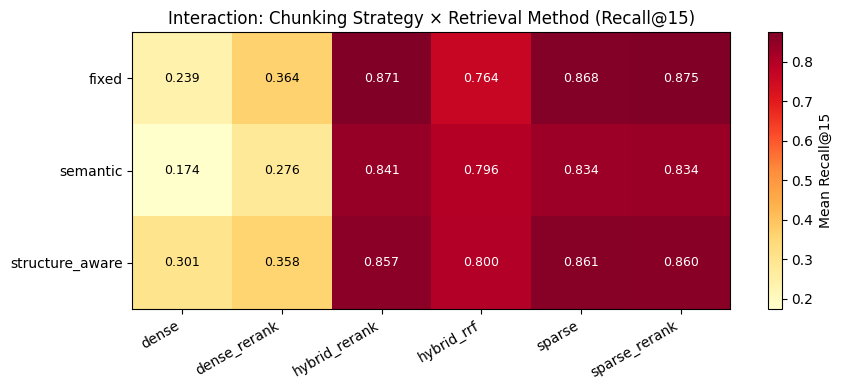

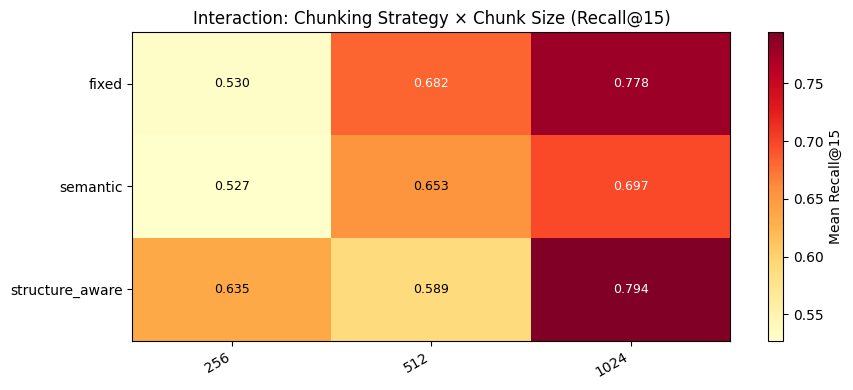

In [7]:
# ---------------------------------------------------------------------------
# Interaction heatmaps: mean Recall@15 for each pairwise factor combination.
#
# We produce three heatmaps:
#   1. chunk_size × retrieval_method (do larger chunks help all methods equally?)
#   2. chunk_strategy × retrieval_method (does BM25 advantage hold for all strategies?)
#   3. chunk_strategy × chunk_size (does size matter equally for all strategies?)
#
# Annotated cell values allow exact comparison in the thesis.
# ---------------------------------------------------------------------------

pivot_size_method = df.pivot_table(values="recall@15", index="chunk_size",
                                    columns="retrieval_method", aggfunc="mean")
pivot_strategy_method = df.pivot_table(values="recall@15", index="chunk_strategy",
                                       columns="retrieval_method", aggfunc="mean")
pivot_strategy_size = df.pivot_table(values="recall@15", index="chunk_strategy",
                                      columns="chunk_size", aggfunc="mean")


def plot_heatmap(pivot_df, title, filename=None):
    """Annotated heatmap suitable for direct inclusion in a thesis."""
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(pivot_df.values, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(len(pivot_df.columns)))
    ax.set_xticklabels(list(pivot_df.columns), rotation=30, ha="right")
    ax.set_yticks(range(len(pivot_df.index)))
    ax.set_yticklabels(list(pivot_df.index))
    ax.set_title(title, fontsize=12)

    # Annotate each cell with its value.
    for i in range(pivot_df.shape[0]):
        for j in range(pivot_df.shape[1]):
            ax.text(j, i, f"{pivot_df.values[i, j]:.3f}",
                    ha="center", va="center", fontsize=9,
                    color="white" if pivot_df.values[i, j] > pivot_df.values.mean() else "black")

    fig.colorbar(im, ax=ax, label="Mean Recall@15")
    plt.tight_layout()
    if filename:
        plt.savefig(RQ1_RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_heatmap(pivot_size_method,
             "Interaction: Chunk Size × Retrieval Method (Recall@15)",
             "heatmap_size_method.png")
plot_heatmap(pivot_strategy_method,
             "Interaction: Chunking Strategy × Retrieval Method (Recall@15)",
             "heatmap_strategy_method.png")
plot_heatmap(pivot_strategy_size,
             "Interaction: Chunking Strategy × Chunk Size (Recall@15)",
             "heatmap_strategy_size.png")

## 7. Winner Selection and Robustness Check

The winning configuration is selected by **Recall@15** (primary metric). As a robustness check, we also rank configurations by **Budgeted Recall@4096** which normalizes for chunk size by accumulating retrieved chunks until a 4096-token budget is reached. If the same configuration wins under both metrics, the conclusion is considered robust.

In [8]:
# ---------------------------------------------------------------------------
# Winner selection by the primary metric (Recall@15).
# Robustness check: also rank by Budgeted Recall@4096, which normalises
# for chunk size by imposing a fixed 4096-token budget. If both metrics
# agree on the winner, the conclusion is considered robust.
#
# The rank_delta column shows how much each config's rank changes between
# the two metrics. Large deltas indicate configs that benefit from the
# token budget normalisation (or are penalised by it).
# ---------------------------------------------------------------------------
rank_primary = df[["config_id", "recall@15"]].sort_values("recall@15", ascending=False).reset_index(drop=True)
rank_budget = df[["config_id", "budgeted_recall@4096"]].sort_values("budgeted_recall@4096", ascending=False).reset_index(drop=True)

print("Winner by Recall@15:          ", rank_primary.iloc[0].to_dict())
print("Winner by Budgeted Recall@4096:", rank_budget.iloc[0].to_dict())

if rank_primary.iloc[0]["config_id"] == rank_budget.iloc[0]["config_id"]:
    print("\n✓ Same winner under both metrics — conclusion is robust.")
else:
    print(f"\n⚠ Winners differ — discuss the trade-off in the thesis.")

# Build a merged comparison table with rank deltas.
comparison = rank_primary.merge(rank_budget, on="config_id",
                                suffixes=("_primary", "_budget"))
comparison["primary_rank"] = comparison["recall@15"].rank(ascending=False, method="min").astype(int)
comparison["budget_rank"] = comparison["budgeted_recall@4096"].rank(ascending=False, method="min").astype(int)
comparison["rank_delta"] = (comparison["primary_rank"] - comparison["budget_rank"]).abs()
comparison.sort_values("primary_rank").head(15)

Winner by Recall@15:           {'config_id': 'fixed_1024_sparse', 'recall@15': 0.948937908496732}
Winner by Budgeted Recall@4096: {'config_id': 'semantic_512_sparse_rerank', 'budgeted_recall@4096': 0.8402777777777778}

⚠ Winners differ — discuss the trade-off in the thesis.


,config_id,recall@15,budgeted_recall@4096,primary_rank,budget_rank,rank_delta
0,fixed_1024_sparse,0.948938,0.820098,1,8,7
1,fixed_1024_hybrid_rerank,0.941176,0.768791,2,25,23
2,fixed_1024_sparse_rerank,0.937908,0.765931,3,26,23
3,structure_aware_1024_sparse,0.919526,0.813725,4,12,8
4,structure_aware_1024_sparse_rerank,0.915033,0.792075,5,17,12
5,structure_aware_1024_hybrid_rerank,0.912582,0.797794,6,16,10
6,fixed_512_sparse_rerank,0.911356,0.815768,7,10,3
7,semantic_1024_sparse,0.904412,0.810703,8,13,5
8,semantic_1024_hybrid_rerank,0.903431,0.805392,9,14,5
9,fixed_512_hybrid_rerank,0.897059,0.817402,10,9,1


## 8. Per-ESRS Standard Breakdown and Chunk Statistics

The winner's **per-standard metrics** reveal whether certain ESRS standards are harder to retrieve for. Quantitative standards (e.g. ESRS E3: water consumption) tend to use structured, keyword-rich language that BM25 captures well. Qualitative standards (e.g. ESRS S1: workforce) may use more descriptive language that is harder to match.

The **chunk statistics** show how each strategy/size combination distributes chunk lengths. Key indicators: mean tokens (how close to the target?), standard deviation (how variable?), and min/max (any degenerate chunks?).

All 12 ESRS standards have annotated evidence passages in the current golden standard. The per-standard breakdown below covers the full evaluation set.

In [9]:
# ---------------------------------------------------------------------------
# Per-ESRS standard breakdown for the winning configuration.
# This reveals which of the 12 standards are easiest/hardest to retrieve.
# ---------------------------------------------------------------------------
winner_path = RQ1_RESULTS_DIR / "rq1_winner.json"
winner_payload = json.loads(winner_path.read_text(encoding="utf-8"))

print(f"Winner: {winner_payload['config_id']}")
if "evaluation_coverage" in winner_payload:
    cov = winner_payload["evaluation_coverage"]
    print(f"Evaluation coverage: {cov['n_evaluated']}/{cov['n_total']} samples "
          f"({cov['n_skipped']} skipped — no annotated evidence)")
    threshold = cov.get("relevance_threshold", 0.5)
    print(f"Relevance threshold: {threshold}")

# --- Winner aggregate metrics ---
print("\nWinner aggregate metrics:")
display(pd.DataFrame([winner_payload["metrics"]]))

# --- Per-standard breakdown ---
print("\nPer-ESRS standard breakdown (winner):")
per_std_df = pd.DataFrame(winner_payload["per_standard_metrics"]).T
per_std_df = per_std_df.sort_values("recall@15", ascending=False)
display(per_std_df)

# --- Chunk statistics for all 9 strategy/size combinations ---
print("\nChunk statistics by strategy and size:")
chunk_stats_files = sorted(RQ1_RESULTS_DIR.glob("chunk_stats_*.json"))
chunk_stats_rows = [
    json.loads(p.read_text(encoding="utf-8")) | {"config": p.stem.replace("chunk_stats_", "")}
    for p in chunk_stats_files
]
if chunk_stats_rows:
    cs_df = pd.DataFrame(chunk_stats_rows).sort_values("total_chunks", ascending=False)
    display(cs_df)

# --- Relevance matching diagnostics ---
# These counters show how many relevance checks used the span-based vs.
# token-overlap fallback path, and how many resulted in hits.
diag = winner_payload.get("evaluation_coverage", {}).get("match_diagnostics")
if diag:
    print(f"\nRelevance matching diagnostics (winner config):")
    print(f"  Span-based checks:     {diag['span_checks']:,}  (hits: {diag['span_hits']:,})")
    print(f"  Token-fallback checks: {diag['token_fallback_checks']:,}  (hits: {diag['token_fallback_hits']:,})")
    print(f"  Span path ratio:       {diag.get('span_path_ratio', 0):.1%}")
    print(f"  Gold span misses:      {diag.get('gold_span_misses', 0):,}")
    print(f"  Short evidence skips:  {diag.get('short_evidence_skips', 0):,}")

Winner: fixed_1024_sparse
Evaluation coverage: 204/204 samples (0 skipped — no annotated evidence)
Relevance threshold: 0.5

Winner aggregate metrics:


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,f1@5,f1@10,f1@15,ndcg@10,mrr@10,budgeted_recall@4096,recall@15_std,precision@15_std,f1@15_std,ndcg@10_std,mrr@10_std
0,0.868709,0.923203,0.948938,0.669608,0.578922,0.526797,0.723851,0.669538,0.627218,0.790158,0.881378,0.820098,0.162131,0.296672,0.275182,0.212974,0.256741



Per-ESRS standard breakdown (winner):


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,f1@5,f1@10,f1@15,ndcg@10,mrr@10,budgeted_recall@4096
ESRS E3,0.941176,0.970588,1.000000,0.611765,0.452941,0.372549,0.707049,0.572088,0.491300,0.892455,0.949580,0.892157
ESRS E4,0.949020,1.000000,1.000000,0.905882,0.823529,0.721569,0.912372,0.879797,0.807168,0.923801,0.960784,0.890196
ESRS 2,0.872549,0.970588,0.970588,0.647059,0.617647,0.552941,0.715087,0.707021,0.650964,0.763289,0.791667,0.857843
ESRS S1,0.823529,0.911765,0.970588,0.505882,0.382353,0.301961,0.616013,0.522696,0.447409,0.715927,0.774510,0.823529
ESRS 1,0.862745,0.921569,0.960784,0.788235,0.723529,0.686275,0.794725,0.752537,0.739619,0.879226,0.901961,0.803922
ESRS E2,0.784314,0.901961,0.960784,0.658824,0.547059,0.501961,0.681842,0.646987,0.610458,0.783997,0.901961,0.725490
ESRS S3,0.921569,0.921569,0.960784,0.705882,0.535294,0.462745,0.781405,0.652415,0.591002,0.773857,0.852941,0.882353
ESRS G1,0.897059,0.960784,0.960784,0.717647,0.641176,0.615686,0.765106,0.739918,0.710539,0.794892,0.941176,0.852941
ESRS S4,0.941176,0.941176,0.941176,0.658824,0.588235,0.588235,0.750591,0.700981,0.702883,0.714446,0.911765,0.911765
ESRS E5,0.843137,0.862745,0.892157,0.435294,0.311765,0.247059,0.543113,0.436717,0.370310,0.712446,0.805882,0.784314



Chunk statistics by strategy and size:


,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens,median_tokens,p25_tokens,p75_tokens,config
4,13360,183.168338,78.594396,2,258,216,124,255,semantic_256
7,12358,210.485677,76.214635,2,258,256,176,256,structure_aware_256
1,10445,255.767544,5.125552,36,259,256,256,256,fixed_256
5,7874,306.389510,176.852802,2,514,331,140,489,semantic_512
8,7497,340.823263,186.810397,2,514,427,155,512,structure_aware_512
3,5466,435.862605,356.747728,2,1025,319,125,784,semantic_1024
6,5337,467.872775,382.334945,2,1026,336,130,941,structure_aware_1024
2,5226,511.195561,13.942560,197,515,512,512,512,fixed_512
0,2617,1020.682461,44.835892,199,1026,1024,1024,1024,fixed_1024



Relevance matching diagnostics (winner config):
  Span-based checks:     4,017  (hits: 374)
  Token-fallback checks: 5,368  (hits: 2,597)
  Span path ratio:       42.8%
  Gold span misses:      5,365
  Short evidence skips:  0


## 9. Statistical Significance Testing

To ensure observed performance differences between top configurations are not due to random variation, we compute:

1. **Bootstrap confidence intervals** (percentile method, 10 000 resamples) for the winner's Recall@15.
2. **Paired permutation tests** (two-sided, 10 000 permutations) comparing the winner against runner-up configurations on the same 204 evaluation samples.
3. **Cohen's d effect size** for each pairwise comparison to quantify practical significance.

A difference is deemed statistically significant at α = 0.05. Effect sizes are interpreted as: small (d ≈ 0.2), medium (d ≈ 0.5), large (d ≈ 0.8).

In [10]:
# ---------------------------------------------------------------------------
# Statistical significance testing for the top configurations.
#
# We load per-sample metrics from the config_details/*.json files so that
# we can run paired tests (same 204 samples across configurations).
#
# Bootstrap CIs give us confidence bounds on the winner's reported metrics.
# Paired permutation tests determine whether the winner is significantly
# better than the runners-up, controlling for query difficulty variation.
# Cohen's d provides a standardised measure of effect magnitude.
# ---------------------------------------------------------------------------
from rag.evaluation.statistical_tests import (
    bootstrap_ci,
    paired_permutation_test,
    compare_top_configs,
)

# Load per-sample recall@15 from each config's detail file.
config_details_dir = RQ1_RESULTS_DIR / "config_details"
per_sample_recall = {}

for path in sorted(config_details_dir.glob("*.json")):
    try:
        payload = json.loads(path.read_text(encoding="utf-8"))
        config_id = payload["config_id"]
        per_sample = payload.get("details", {}).get("per_sample_metrics", [])
        if per_sample:
            per_sample_recall[config_id] = [s["recall@15"] for s in per_sample]
    except Exception:
        continue

print(f"Loaded per-sample metrics for {len(per_sample_recall)} configurations")

if per_sample_recall:
    # --- Bootstrap CI for the winner ---
    winner_id = winner_payload["config_id"]
    if winner_id in per_sample_recall:
        winner_values = per_sample_recall[winner_id]
        ci = bootstrap_ci(winner_values, metric_name="recall@15")
        print(f"\n{'='*60}")
        print(f"Winner: {winner_id}")
        print(f"  Recall@15 = {ci.mean:.4f}  (95% CI: [{ci.ci_lower:.4f}, {ci.ci_upper:.4f}])")
        print(f"  Std dev   = {ci.std:.4f}  (n = {ci.n_samples} samples)")
        print(f"{'='*60}")

    # --- Paired permutation tests: winner vs. top-5 runners-up ---
    print("\nPairwise comparisons (winner vs. runners-up):\n")
    ranked_ids = df.sort_values("recall@15", ascending=False)["config_id"].tolist()
    top_ids = [cid for cid in ranked_ids[:6] if cid in per_sample_recall]

    test_results = []
    for cid in top_ids:
        if cid == winner_id:
            continue
        if cid not in per_sample_recall:
            continue
        result = paired_permutation_test(
            per_sample_recall[winner_id],
            per_sample_recall[cid],
            config_a=winner_id,
            config_b=cid,
            metric_name="recall@15",
        )
        test_results.append(result)
        sig_marker = "***" if result.p_value < 0.001 else "**" if result.p_value < 0.01 else "*" if result.p_value < 0.05 else "n.s."
        print(f"  {winner_id} vs {cid}:")
        print(f"    Δ = {result.observed_diff:+.4f},  p = {result.p_value:.4f} {sig_marker},  Cohen's d = {result.effect_size:.3f}")

    # Summary table for thesis.
    if test_results:
        print("\n\nSummary table (for thesis):")
        sig_df = pd.DataFrame([{
            "Config A": r.config_a,
            "Config B": r.config_b,
            "Mean A": round(r.mean_a, 4),
            "Mean B": round(r.mean_b, 4),
            "Δ": round(r.observed_diff, 4),
            "p-value": round(r.p_value, 4),
            "Significant": "Yes" if r.significant else "No",
            "Cohen's d": round(r.effect_size, 3),
        } for r in test_results])
        display(sig_df)
else:
    print("Per-sample metrics not available. Re-run the evaluation to generate them.")

Loaded per-sample metrics for 54 configurations

Winner: fixed_1024_sparse
  Recall@15 = 0.9489  (95% CI: [0.9248, 0.9698])
  Std dev   = 0.1621  (n = 204 samples)

Pairwise comparisons (winner vs. runners-up):

  fixed_1024_sparse vs fixed_1024_hybrid_rerank:
    Δ = +0.0078,  p = 0.4251 n.s.,  Cohen's d = 0.057
  fixed_1024_sparse vs fixed_1024_sparse_rerank:
    Δ = +0.0110,  p = 0.3734 n.s.,  Cohen's d = 0.065
  fixed_1024_sparse vs structure_aware_1024_sparse:
    Δ = +0.0294,  p = 0.0014 **,  Cohen's d = 0.218
  fixed_1024_sparse vs structure_aware_1024_sparse_rerank:
    Δ = +0.0339,  p = 0.0074 **,  Cohen's d = 0.185
  fixed_1024_sparse vs structure_aware_1024_hybrid_rerank:
    Δ = +0.0364,  p = 0.0025 **,  Cohen's d = 0.209


Summary table (for thesis):


,Config A,Config B,Mean A,Mean B,Δ,p-value,Significant,Cohen's d
0,fixed_1024_sparse,fixed_1024_hybrid_rerank,0.9489,0.9412,0.0078,0.4251,No,0.057
1,fixed_1024_sparse,fixed_1024_sparse_rerank,0.9489,0.9379,0.0110,0.3734,No,0.065
2,fixed_1024_sparse,structure_aware_1024_sparse,0.9489,0.9195,0.0294,0.0014,Yes,0.218
3,fixed_1024_sparse,structure_aware_1024_sparse_rerank,0.9489,0.9150,0.0339,0.0074,Yes,0.185
4,fixed_1024_sparse,structure_aware_1024_hybrid_rerank,0.9489,0.9126,0.0364,0.0025,Yes,0.209


## 10. Summary

This notebook evaluated **54 RAG configurations** (3 chunking strategies × 3 chunk sizes × 6 retrieval methods) against a golden standard of 204 question–company pairs covering all 12 ESRS standards.

**Key outputs saved to `data/artifacts/evaluation_results/rq1/`:**
- `rq1_config_results.csv` / `.json` — all 54 configuration scores
- `rq1_winner.json` — winning configuration with per-standard breakdown
- `config_details/*.json` — per-config detailed results including per-sample metrics
- `chunk_stats_*.json` — chunk distribution statistics for each strategy/size
- `main_effects_recall15.png` — main effects bar chart
- `heatmap_*.png` — interaction heatmaps

**The winning configuration is written to `config/best_pipeline.yaml`** and is used as the fixed retrieval pipeline for RQ2 (ESRS context injection) and RQ3 (generation quality evaluation).